# RouteRanker – Module 2: Feature Engineering
**Purpose:** turn the raw GTFS files collected in Module 1 into features that describe how bus routes are *scheduled* – trip counts, distinct stops, time-of-day patterns, headways, route length.

**Important limitation:** GTFS describes planned service. It contains **no passenger counts or occupancy**, so no feature here is a passenger or demand figure. `n_trips` means *scheduled trips*, nothing more. A route with few trips is not automatically inefficient.

The notebook runs the steps one by one on a single city (change `CITY` below). `run_module2.py` repeats the same logic for all 7 cities.

In [1]:
import os, sys
import numpy as np, pandas as pd
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
sys.path.insert(0, os.getcwd())
from src import cleaning, inspect_gtfs as ig, module2_features as m2
from src.gtfs_loader import gtfs_time_to_sec
pd.set_option("display.max_columns", 40, "display.width", 200)

CITY = "pune"        # any folder in data/raw/: ahmedabad, bengaluru, chennai, delhi, hyderabad, kochi, pune
CITY_DIR = f"data/raw/{CITY}"
print("working on:", CITY)

working on: pune


## Step 1 – Load and inspect the raw GTFS files
Raw files stay untouched in `data/raw/`; everything below works on copies in memory.

In [2]:
raw = cleaning.load_raw(CITY_DIR)
shapes = ig.read_file(CITY_DIR, "shapes")            # optional file, read separately (it is large)
pd.DataFrame([dict(file=n + ".txt", rows=len(df), columns=df.shape[1]) for n, df in {**raw, **({"shapes": shapes} if shapes is not None else {})}.items()])

,file,rows,columns
0,routes.txt,315,5
1,trips.txt,10128,6
2,stop_times.txt,429302,6
3,stops.txt,6745,4
4,calendar.txt,1,10
5,shapes.txt,256823,4


In [3]:
for n in ["routes", "trips", "stop_times", "stops", "calendar"]:
    print(f"--- {n}.txt"); display(raw[n].head(3))

--- routes.txt


,route_id,agency_id,route_short_name,route_long_name,route_type
0,100,PMPML,100,Hinjawadi Maan Phase 3 ⇆ Ma Na Pa Dengle Pul N...,3
1,103,PMPML,103,Kothrud Depot ⇆ Katraj,3
2,104,PMPML,104,Dsk Vishwa ⇆ Shivaji Nagar,3


--- trips.txt


,route_id,service_id,trip_id,trip_headsign,direction_id,shape_id
0,108,WEEKDAY,trip_18_0,Sutardara,0,18
1,108,WEEKDAY,trip_18_1,Sutardara,0,18
2,108,WEEKDAY,trip_18_2,Sutardara,0,18


--- stop_times.txt


,trip_id,arrival_time,departure_time,stop_id,stop_sequence,timepoint
0,trip_18_0,08:30:00,08:30:00,106793,1,1
1,trip_18_0,08:31:00,08:31:00,319,2,0
2,trip_18_0,08:33:09,08:33:09,320,3,0


--- stops.txt


,stop_id,stop_name,stop_lat,stop_lon
0,106793,Pune Station Moledina Road,18.527575,73.873245
1,319,Income Tax Office,18.525400,73.876701
2,320,Gpo,18.523537,73.875557


--- calendar.txt


,service_id,monday,tuesday,wednesday,thursday,friday,saturday,sunday,start_date,end_date
0,WEEKDAY,1,1,1,1,1,1,1,20261007,20270405


## Step 2 – Time-based features
GTFS writes times as `HH:MM:SS`, and **HH can be 24 or more** for trips that run past midnight (e.g. `25:10:00` = 01:10 the next day). So the strings are first converted to *seconds since the start of the service day*; the clock hour is then `(seconds // 3600) % 24`. Missing or invalid values become `NaN` (they are not turned into zero).

In [4]:
demo = pd.Series(["08:30:00", "23:59:00", "24:05:00", "25:10:00", "", "xx:yy:zz"])
pd.DataFrame({"gtfs_time": demo, "seconds": gtfs_time_to_sec(demo),
              "clock_hour": (gtfs_time_to_sec(demo) // 3600) % 24})

,gtfs_time,seconds,clock_hour
0,08:30:00,30600.0,8.0
1,23:59:00,86340.0,23.0
2,24:05:00,86700.0,0.0
3,25:10:00,90600.0,1.0
4,,NaN,NaN
5,xx:yy:zz,NaN,NaN


**Time periods (fixed rules):** morning 05:00–11:59 · afternoon 12:00–16:59 · evening 17:00–20:59 · night 21:00–04:59, based on the trip's first departure.

In [5]:
pd.DataFrame({"hour": range(24), "period": m2.period_of(range(24))}).groupby("period").hour.agg(["min", "max", "count"])

,min,max,count
period,,,
afternoon,12,16,5
evening,17,20,4
morning,5,11,7
night,0,23,8


## Step 3 – Data-quality checks *before* cleaning
Findings only – nothing is changed yet. Missing values are not replaced by zero because zero could be a valid value with a different meaning.

In [6]:
checks = {}
for n in ["routes", "trips", "stops", "stop_times"]:
    df = raw[n]
    checks[n] = dict(rows=len(df), cells_missing=int(df.isna().sum().sum()), fully_duplicated_rows=int(df.duplicated().sum()))
checks["routes"]["duplicate_route_id"] = int(raw["routes"].route_id.duplicated().sum())
checks["trips"]["duplicate_trip_id"] = int(raw["trips"].trip_id.duplicated().sum())
checks["stops"]["duplicate_stop_id"] = int(raw["stops"].stop_id.duplicated().sum())
lat = pd.to_numeric(raw["stops"].stop_lat, errors="coerce"); lon = pd.to_numeric(raw["stops"].stop_lon, errors="coerce")
checks["stops"]["invalid_coordinates"] = int((lat.isna() | lon.isna() | ~lat.between(6, 37) | ~lon.between(68, 98)).sum())
t = gtfs_time_to_sec(raw["stop_times"].arrival_time)
checks["stop_times"]["unparseable_arrival_times"] = int((t.isna() & raw["stop_times"].arrival_time.notna()).sum())
checks["stop_times"]["times_>=_24h (valid GTFS)"] = int((t >= 86400).sum())
checks["trips"]["trip_without_stop_times"] = int((~raw["trips"].trip_id.isin(raw["stop_times"].trip_id)).sum())
pd.DataFrame(checks).T.fillna("")

,rows,cells_missing,fully_duplicated_rows,duplicate_route_id,duplicate_trip_id,trip_without_stop_times,duplicate_stop_id,invalid_coordinates,unparseable_arrival_times,times_>=_24h (valid GTFS)
routes,315.0,0.0,0.0,0.0,,,,,,
trips,10128.0,0.0,0.0,,0.0,0.0,,,,
stops,6745.0,0.0,0.0,,,,0.0,0.0,,
stop_times,429302.0,0.0,0.0,,,,,,0.0,179.0


## Step 4 – Cleaning, with a log of every action
Each step records how many rows it affected and why. Original files are not modified.

In [7]:
clean, log = cleaning.clean_city(raw, CITY)
log[log.rows_changed > 0][["table", "step", "action", "rows_before", "rows_after", "reason"]]

,table,step,action,rows_before,rows_after,reason


## Step 5 – Counting correctly: distinct trips ≠ rows of `stop_times.txt`
One trip has many `stop_times` rows (one per stop). Counting rows would massively overstate service, so trips are counted with `nunique()`.

In [8]:
route_example = clean["trips"].route_id.value_counts().index[0]
rows = clean["stop_times"].merge(clean["trips"][["trip_id", "route_id"]], on="trip_id").query("route_id == @route_example")
pd.Series({"route_id": route_example, "stop_times rows": len(rows), "DISTINCT trips (correct trip count)": rows.trip_id.nunique(),
           "distinct stops": rows.stop_id.nunique()})

route_id                                  5
stop_times rows                        2534
DISTINCT trips (correct trip count)     175
distinct stops                           27
dtype: object

## Step 6 – Aggregation with `groupby` / `nunique`
Distinct scheduled trips and distinct stops per route, written out explicitly:

In [9]:
st_r = clean["stop_times"].merge(clean["trips"][["trip_id", "route_id"]], on="trip_id")
agg = st_r.groupby("route_id").agg(distinct_trips=("trip_id", "nunique"), distinct_stops=("stop_id", "nunique")).reset_index()
agg.sort_values("distinct_trips", ascending=False).head(5)

,route_id,distinct_trips,distinct_stops
246,5,175,27
8,114,116,82
292,H8,110,28
201,350,109,50
66,167,107,66


## Step 7 – Build all features
`build_all` creates trip-level features, the route × hour table, stop usage and the route profile (`route_features`).

In [10]:
out = m2.build_all(clean, shapes)
{k: v.shape for k, v in out.items()}

{'trip_features': (10128, 25),
 'route_hour_features': (3536, 8),
 'stop_usage': (6745, 8),
 'route_features': (315, 47)}

In [11]:
out["trip_features"][["trip_id", "route_id", "departure_clock", "start_hour", "period", "starts_after_midnight", "duration_min", "service_day_type"]].head()

,trip_id,route_id,departure_clock,start_hour,period,starts_after_midnight,duration_min,service_day_type
0,trip_18_0,108,08:30,8,morning,False,35.000000,weekday_and_weekend
1,trip_18_1,108,10:30,10,morning,False,35.000000,weekday_and_weekend
2,trip_18_2,108,12:30,12,afternoon,False,35.000000,weekday_and_weekend
3,trip_19_0,108,07:40,7,morning,False,36.166667,weekday_and_weekend
4,trip_19_1,108,09:25,9,morning,False,36.166667,weekday_and_weekend


In [12]:
out["route_hour_features"].sort_values(["route_id", "hour"]).head(8)

,route_id,hour,trips_all,trips_typical_weekday,trips_typical_sunday,median_headway_min,scheduled_stop_visits,period
0,100,4,1,1.0,1.0,NaN,9,night
1,100,5,5,5.0,5.0,15.0,136,morning
2,100,6,7,7.0,7.0,15.0,301,morning
3,100,7,7,7.0,7.0,10.0,358,morning
4,100,8,10,10.0,10.0,5.0,437,morning
5,100,9,9,9.0,9.0,10.0,490,morning
6,100,10,7,7.0,7.0,10.0,410,morning
7,100,11,8,8.0,8.0,7.5,363,morning


**Hourly pattern:** distinct scheduled trips starting in each clock hour (supply, not demand).

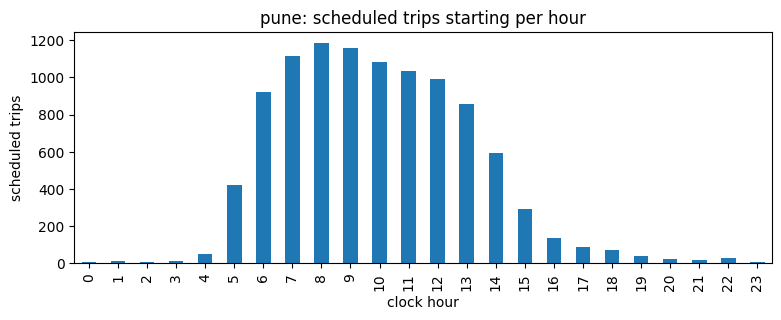

In [13]:
out["route_hour_features"].groupby("hour").trips_all.sum().plot(kind="bar", figsize=(9, 3), title=f"{CITY}: scheduled trips starting per hour", xlabel="clock hour", ylabel="scheduled trips");

## Step 8 – Route length: `shapes.txt` first, stop coordinates as fallback
Straight-line distance between stops is *not* road distance, so the shape path is used when the feed has one and it passes a sanity check (0.5×–3× the stop-based length).

In [14]:
rf = out["route_features"]
print("shapes.txt available:", shapes is not None)
display(rf.length_method.value_counts().to_frame("routes"))
rf[["route_id", "route_name", "length_km_stops", "length_km_shape", "length_km", "length_method"]].dropna(subset=["length_km_shape"]).head() if shapes is not None else rf[["route_id", "length_km_stops", "length_km"]].head()

shapes.txt available: True


,routes
length_method,
shapes.txt,313
stop coordinates (shape failed sanity check),2


,route_id,route_name,length_km_stops,length_km_shape,length_km,length_method
0,100,100,24.790853,26.454707,26.454707,shapes.txt
1,103,103,13.495506,14.073425,14.073425,shapes.txt
2,104,104,15.303425,16.486164,16.486164,shapes.txt
3,107,107,22.101763,24.135430,24.135430,shapes.txt
4,108,108,9.683627,11.330314,11.330314,shapes.txt


## Step 9 – Trip count, frequency and headway are different things
* **trip count** `n_trips` – distinct scheduled trips · **frequency** `trips_per_active_hour` – scheduled trips per operating hour · **headway** `median_headway_min` – minutes between consecutive departures (same route and service). Headway is *undefined* (missing) for routes with a single departure time.

In [15]:
rf[["route_id", "n_trips", "n_active_hours", "trips_per_active_hour", "median_headway_min"]].sort_values("n_trips", ascending=False).head(5)

,route_id,n_trips,n_active_hours,trips_per_active_hour,median_headway_min
246,5,175,11,15.909091,3.0
8,114,116,16,7.250000,10.0
292,H8,110,15,7.333333,10.0
201,350,109,12,9.083333,10.0
66,167,107,13,8.230769,10.0


## Step 10 – The route profile

In [16]:
one = rf.iloc[(rf.n_trips - rf.n_trips.median()).abs().argsort().iloc[0]]
one.to_frame("value")

,value
route_id,N15
route_name,N15
route_type,3
n_trips,22
median_stops_per_trip,13.0
avg_trip_duration_min,14.166667
median_trip_duration_min,14.166667
n_service_ids,1
trips_from_frequency,0
has_time_backwards_trip,False


## Step 11 – Quality checks on the engineered features

In [17]:
miss = rf.isna().sum(); miss = miss[miss > 0].to_frame("missing"); miss["pct"] = (100 * miss.missing / len(rf)).round(1)
print("duplicate route_id:", int(rf.route_id.duplicated().sum()), "| speed outside 3-80 km/h:", int(rf.speed_implausible.sum()),
      "| routes with a backwards-time trip:", int(rf.has_time_backwards_trip.sum()))
miss

duplicate route_id: 0 | speed outside 3-80 km/h: 2 | routes with a backwards-time trip: 0


,missing,pct


Missing values are *undefined*, not zero: e.g. `median_headway_min` is missing when a route has only one departure time.

In [18]:
rf.describe().T[["count", "min", "50%", "max"]].round(2)

,count,min,50%,max
route_type,315.0,3.00,3.00,3.00
n_trips,315.0,3.00,22.00,175.00
median_stops_per_trip,315.0,8.00,42.00,122.00
avg_trip_duration_min,315.0,10.38,61.91,237.23
median_trip_duration_min,315.0,7.68,62.32,233.50
n_service_ids,315.0,1.00,1.00,1.00
trips_from_frequency,315.0,0.00,0.00,0.00
first_departure_h,315.0,0.00,5.58,9.25
last_departure_h,315.0,9.83,14.83,23.92
n_directions,315.0,1.00,2.00,2.00


## Step 12 – Numerical vs categorical, direct vs derived

In [19]:
from src.feature_dictionary import FEATURES
fd = pd.DataFrame(FEATURES, columns=["table", "feature", "data type", "kind", "direct/derived", "source", "meaning"])
fd[fd.table == "route_features"][["feature", "data type", "kind", "direct/derived", "source"]]

,feature,data type,kind,direct/derived,source
0,city,text,categorical,derived,folder name
1,route_id,text,identifier,direct,routes.txt
2,route_name,text,categorical,derived,routes.txt
3,route_type,integer code,categorical,direct,routes.txt
4,n_trips,integer,numeric,derived,trips.txt (+stop_times.txt)
5,n_unique_stops,integer,numeric,derived,stop_times.txt + trips.txt
6,median_stops_per_trip,float,numeric,derived,stop_times.txt
7,n_service_ids,integer,numeric,derived,trips.txt
8,n_directions,integer,numeric,derived,trips.txt
9,trips_from_frequency,integer,numeric,derived,frequencies.txt


IDs such as `route_id` are identifiers and are never treated as numeric measurements. The full dictionary is in `reports/module2_feature_dictionary.md`.

## Step 13 – Save the feature-engineered dataset
Raw and processed data are kept in separate folders.

In [20]:
os.makedirs(f"data/processed/{CITY}", exist_ok=True)
rf_out = rf.copy(); rf_out.insert(0, "city", CITY)
rf_out.to_csv(f"data/processed/{CITY}/route_features.csv", index=False)
out["route_hour_features"].to_csv(f"data/processed/{CITY}/route_hour_features.csv", index=False)
out["stop_usage"].to_csv(f"data/processed/{CITY}/stop_usage.csv", index=False)
print("saved:", os.listdir(f"data/processed/{CITY}"))

saved: ['route_features.csv', 'cleaning_log.csv', 'trip_features.csv', 'route_hour_features.csv', 'stop_usage.csv']


## Limitations (also in `reports/module2_assumptions_limitations.md`)
* No passenger or occupancy data in GTFS – all features are about the **scheduled** service.
* `n_trips` adds up all service patterns of a feed; use `trips_monday … trips_sunday` for a per-day view. `calendar_dates.txt` exceptions are not applied.
* Route length from stop coordinates is a straight-line lower bound; shapes are used where available.
* Some feeds show signs of generated or duty-level timetables (see the timing-plausibility table in the assumptions report), so durations and headways must be interpreted with care.